In [259]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing  import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

In [260]:
train_df = pd.read_csv('/content/titanic.csv')
#test_df = pd.read_csv('test.csv')

In [261]:
train_df.head(4)
#From common sense, columns such as PassengerId, Name and Ticket number shouldn't be related to the survival probability.
#Cabin has null values too

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S


In [262]:
train_df.info()

#Conclusion:It indicates that there are total of 891 passesnger details among which 177 people's Age is missing and 687 people's Cabin details are missing. And 2 people's Embarkation details are missing.
#Analyis perspective: Drop cabin because of many missing values
#ML Prediction perspective: Keep it

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [263]:
train_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


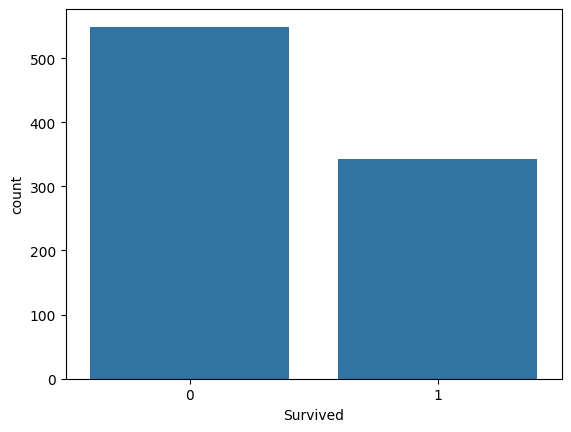

In [264]:
sns.countplot(x='Survived', data=train_df);

In [265]:
train_df['Survived'].value_counts(normalize=True)*100

,proportion
Survived,
0,61.616162
1,38.383838


### Univariate Analysis of Features

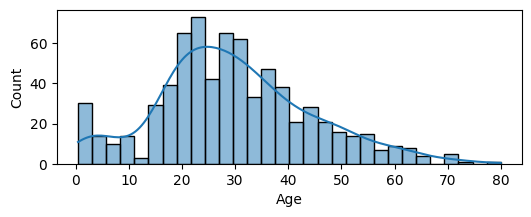

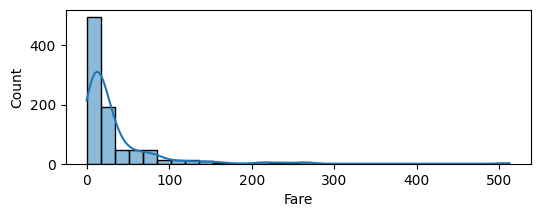

In [266]:
numerical_cols = ['Age', 'Fare']

for col in numerical_cols:
    plt.figure(figsize=(6, 2)) # Create a new figure for each plot
    sns.histplot(train_df[col].dropna(), kde=True, bins=30)
    plt.show() # Display each plot individually

<Axes: >

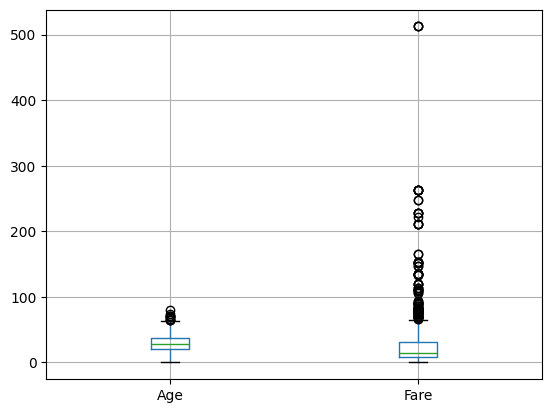

In [267]:
#Also lets check for outliers
train_df.boxplot(column = ['Age','Fare'])
 #we see some outliers in Fare

#### Conclusions from Numerical Feature Histograms:
*   **Age**: The distribution is with a peak around 20-30 years old, which means younger population was comparatively larger.
*   **Fare**: The plot indicates that a large number of population was travelling cheaper with a few exceptions which was a cost more than 450.


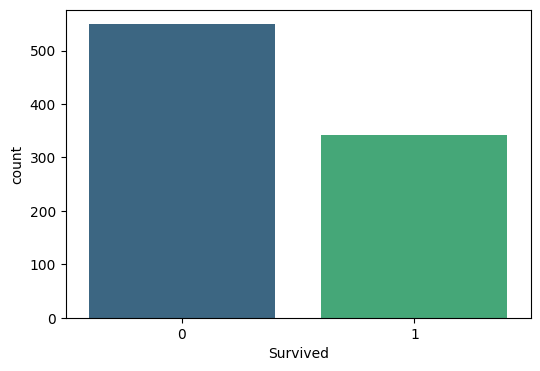

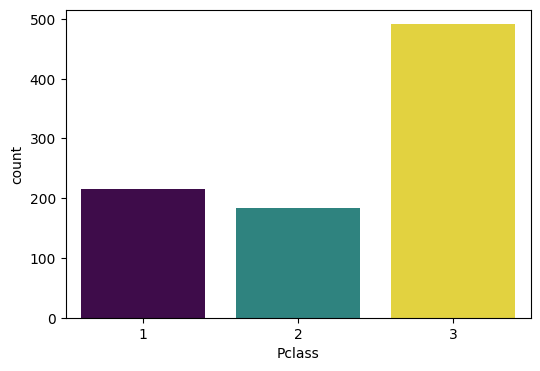

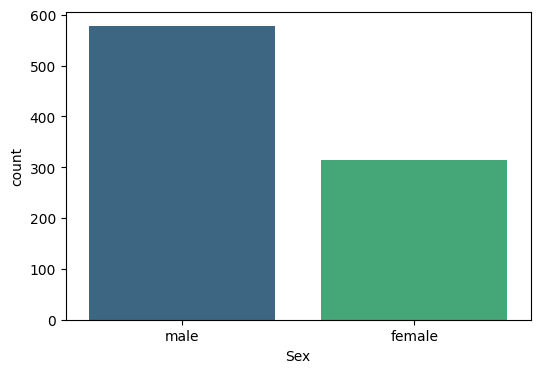

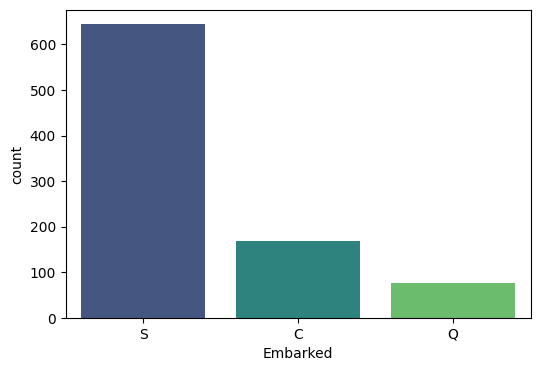

In [268]:
# Categorical Features: Count Plots
categorical_cols = ['Survived', 'Pclass', 'Sex', 'Embarked']

for col in categorical_cols:
    plt.figure(figsize=(6, 4)) # Create a new figure for each plot
    sns.countplot(x=train_df[col].dropna(), palette='viridis', hue=train_df[col].dropna(), legend=False)
    plt.show() # Display each plot individually

#### Conclusions from Categorical Feature Count Plots:
*   **Survived**: More passengers did not survive (0) than survived (1), indicating a survival rate less than 50%.
*   **Pclass**: The majority of passengers were in the 3rd class, followed by 1st and then 2nd class.
*   **Sex**: There were significantly more male passengers than female passengers.
*   **Embarked**: Most passengers embarked from 'S' (Southampton), followed by 'C' (Cherbourg) and 'Q' (Queenstown).


In [269]:
temp_df = train_df.copy()

# Convert 'Pclass', 'SibSp', and 'Parch' to object type
temp_df['Pclass'] = temp_df['Pclass'].astype(str)
temp_df['SibSp'] = temp_df['SibSp'].astype(str)
temp_df['Parch'] = temp_df['Parch'].astype(str)

# Now, describe with include='O' will include these converted columns
display(temp_df.describe(include='O'))

,Pclass,Name,Sex,SibSp,Parch,Ticket,Cabin,Embarked
count,891,891,891,891,891,891,204,889
unique,3,891,2,7,7,681,147,3
top,3,"Dooley, Mr. Patrick",male,0,0,347082,G6,S
freq,491,1,577,608,678,7,4,644


In [270]:
pd.crosstab(train_df['Survived'],train_df['Pclass'],normalize = 'columns')*100

Pclass,1,2,3
Survived,,,
0,37.037037,52.717391,75.763747
1,62.962963,47.282609,24.236253


*   Here we see travellers from Pclass 1 survived were rescued comparatively to 2,3
*  Here we formulate, yet not claimed that wealthy
passengers survived.

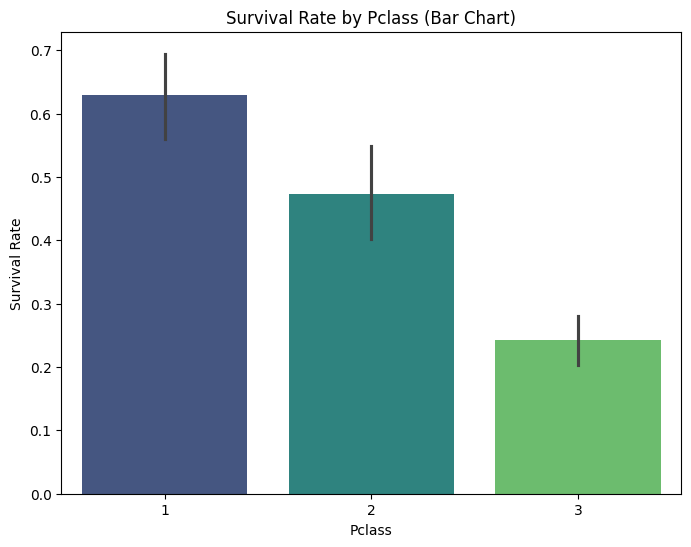

In [271]:
plt.figure(figsize=(8, 6))
sns.barplot(x='Pclass', y='Survived', data=train_df.dropna(subset=['Survived']), palette='viridis')
plt.title('Survival Rate by Pclass (Bar Chart)')
plt.xlabel('Pclass')
plt.ylabel('Survival Rate')
plt.show()

# Observation: This bar chart provides a clear visual comparison of survival rates across different Pclasses, showing that Pclass 1 passengers had a significantly higher survival rate than Pclass 2 and 3.

In [272]:
pd.crosstab(train_df['Survived'],train_df['Sex'],normalize = 'columns')*100
#Females were the priority to be saved

Sex,female,male
Survived,,
0,25.796178,81.109185
1,74.203822,18.890815


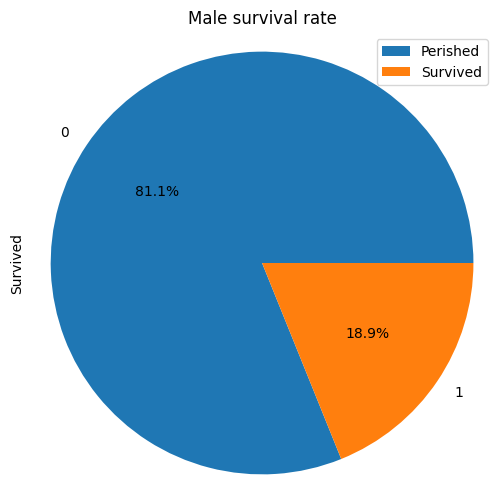

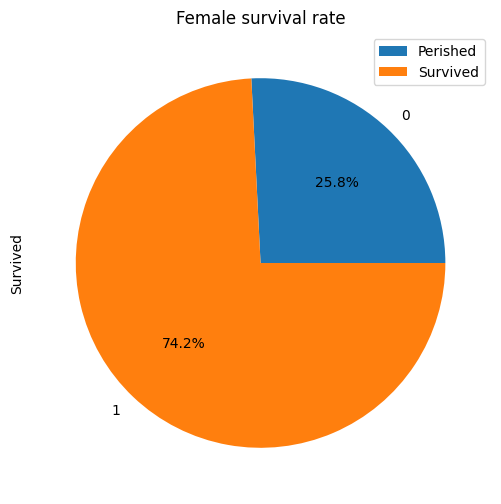

In [273]:
train_df[train_df['Sex'] == 'male'].Survived.groupby(train_df.Survived).count().plot(kind='pie', figsize=(6, 6),autopct='%1.1f%%')
plt.axis('equal')
plt.legend(["Perished","Survived"])
plt.title("Male survival rate")
plt.show()

train_df[train_df['Sex'] == 'female'].Survived.groupby(train_df.Survived).count().plot(kind='pie', figsize=(6, 6),autopct='%1.1f%%')
plt.legend(["Perished","Survived"])
plt.title("Female survival rate")
plt.show()

In [274]:
# To crosstab Survived by both Sex and Pclass, pass them as a list to the columns parameter
pd.crosstab(train_df['Survived'], [train_df['Sex'], train_df['Pclass']], normalize='columns') * 100

Sex          female                        male                      
Pclass            1          2     3          1          2          3
Survived                                                             
0          3.191489   7.894737  50.0  63.114754  84.259259  86.455331
1         96.808511  92.105263  50.0  36.885246  15.740741  13.544669

<Axes: xlabel='Pclass', ylabel='Survived'>

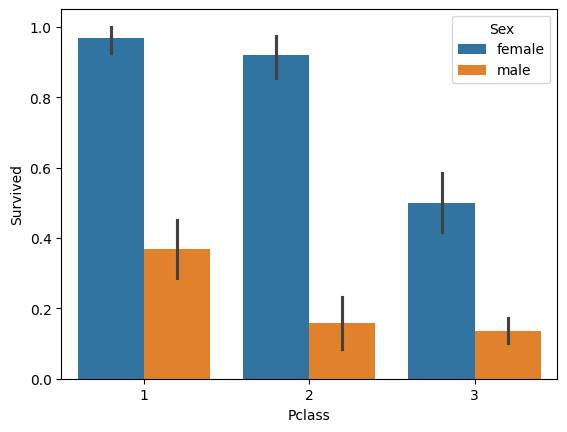

In [275]:
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=train_df)

In [276]:
pd.crosstab(train_df['Survived'],train_df['Embarked'],normalize = 'columns')*100
#Peopel from C survived more(rescued)
#here we think why, because we do not save people according to the place they boarded from
#therefore from our insight that wealthy poeple were saved (Pclass)
#lets check!!

Embarked,C,Q,S
Survived,,,
0,44.642857,61.038961,66.304348
1,55.357143,38.961039,33.695652


In [277]:
pd.crosstab(train_df['Sex'],train_df['Embarked'],normalize = 'columns')*100
#so people were not saved on basis of gender in this comparison.

Embarked,C,Q,S
Sex,,,
female,43.452381,46.753247,31.521739
male,56.547619,53.246753,68.478261


In [278]:
pd.crosstab(train_df['Pclass'],train_df['Embarked'],normalize = 'columns')*100
#Here we clearly see, 50 percent passengers in Cheborg were in 1st class
#Hence they were saved.
#Concluding: SocioEconomic status overruled humanity

Embarked,C,Q,S
Pclass,,,
1,50.595238,2.597403,19.720497
2,10.119048,3.896104,25.465839
3,39.285714,93.506494,54.813665


### Quick Conclusions: Embarked, Sex, & Survived
* **Socioeconomic Influence**: Passengers who embarked from Cherbourg (C) had a much higher survival rate (**55.4%**) because more than half (**50.6%**) were in First Class.
* **Gender Distribution**: The reason survival rates differed between the three departure ports was how wealthy the passengers were, not how many men or women were on board.
While there were more men than women at every single port, what truly mattered was the price of their ticket and the class they traveled in.

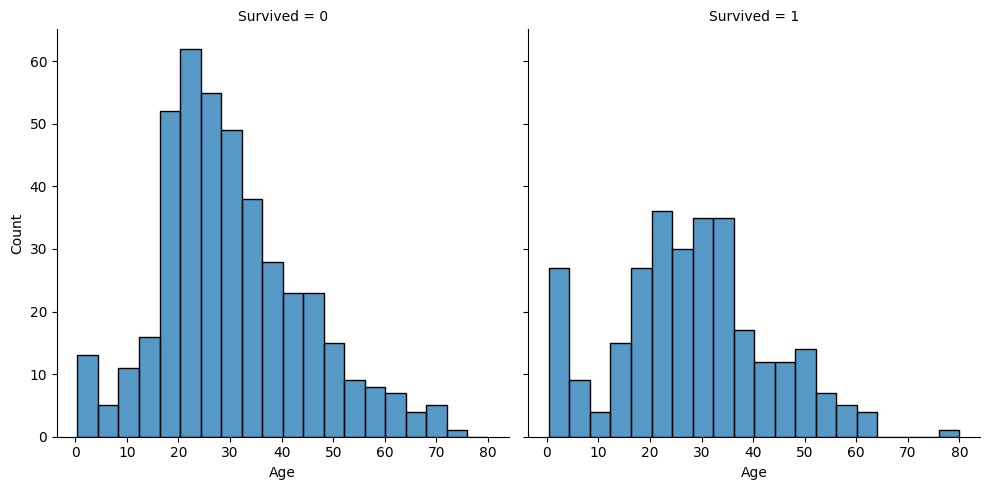

In [279]:
pd.crosstab(train_df['Survived'],train_df['Age'],normalize = 'columns')*100
sns.displot(x='Age', col='Survived', data=train_df.dropna(subset=['Survived', 'Age']), palette='viridis')

#Observation: Here we see approximately 20 to 35 (age range) did not survive
#             infants , teenager and middle age passengers survived, above 65 did not due to elderly age range.

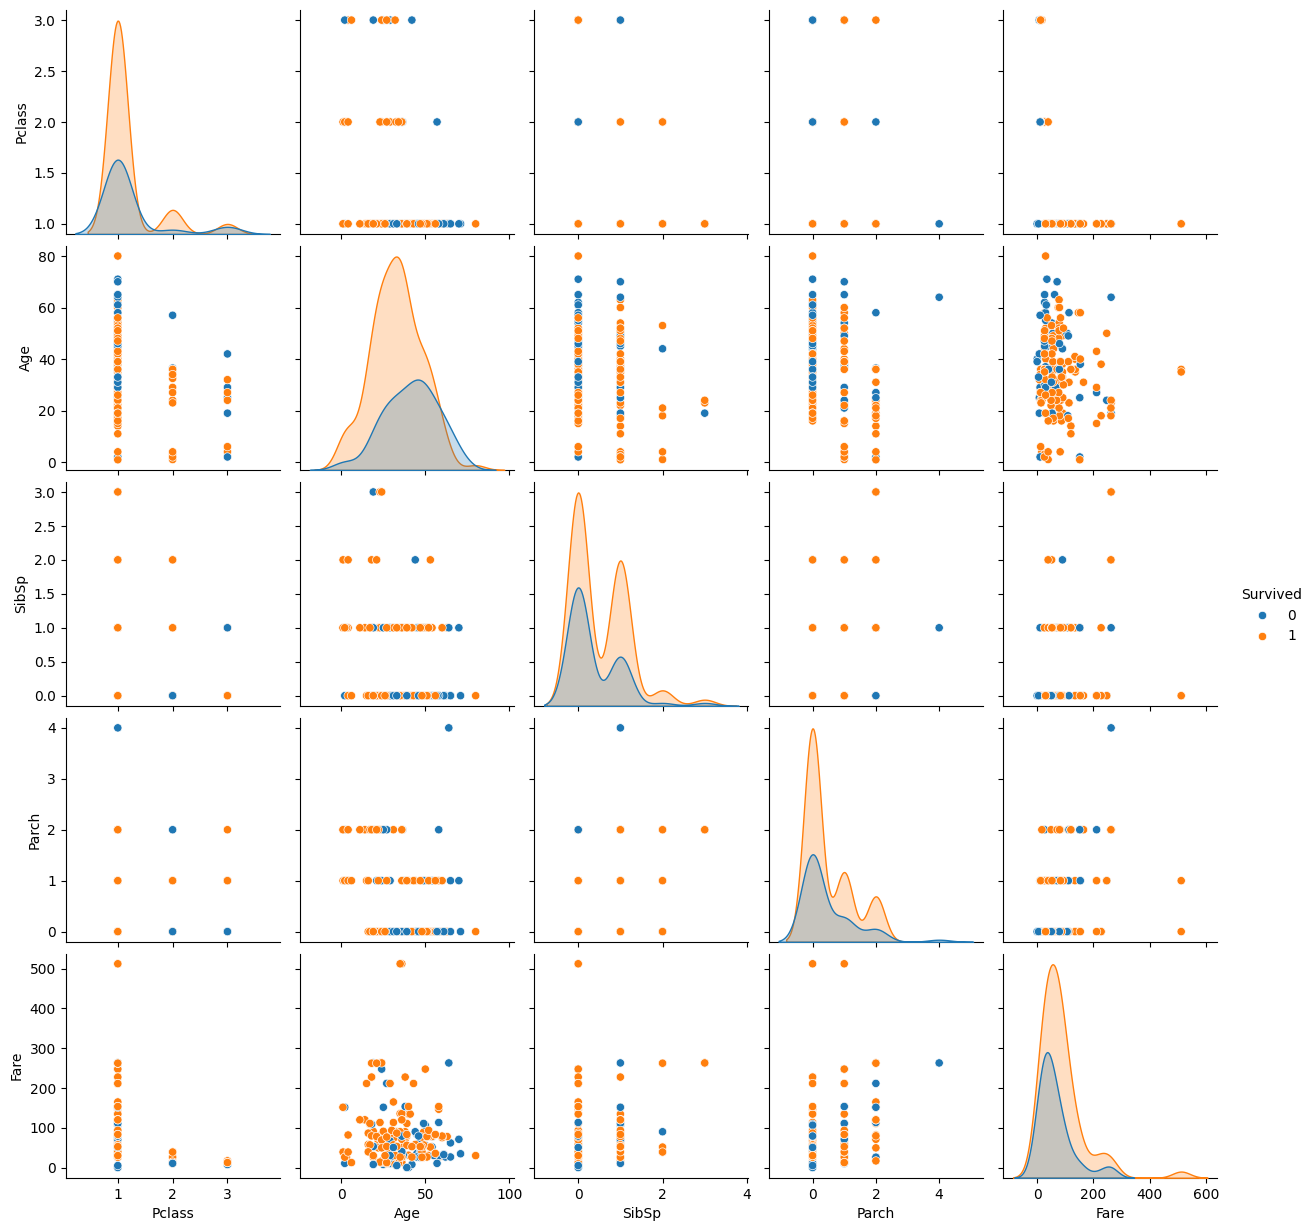

In [280]:
sns.pairplot(train_df.drop(["Name", "PassengerId"],axis = 1).dropna(),hue = "Survived")

Survival on the Titanic was highly non-random, driven primarily by class privilege (wealth), younger age, and traveling with a small family unit.